<div dir="rtl">

### توقّع وقت توصيل الطلبات

- **المشكلة المختارة:** المشكلة 3، التشغيل: متى يصل طلبي؟
- **سبب الاختيار:** اخترت هذه المشكلة لانها قريبة من تجربتي اليومية كمستخدمة لتطبيقات التوصيل، ولفت انتباهي كيف ممكن البيانات تتنبأ بوقت وصول الطلب بدقة وتحسن تجربة العميل
- **الداتا:** `Food Delivery Dataset`، 45,593 طلب و20 عمود
- **الـ Target:** `Time_taken(min)` (وقت التوصيل بالدقائق)
- **الريبو:** https://github.com/Manar-Mohammed8/delivery-time-prediction

</div>

<div dir="rtl">

## 1. فهم المشكلة

**1. من العميل؟ وكم تكلفه المشكلة؟**
العميل هو شركة أو تطبيق توصيل طعام عنده أكثر من 45 ألف طلب في البيانات. المشكلة أن وقت التوصيل يتراوح بين 10 و54 دقيقة، وهذا يعني فيه فرق كبير بين أسرع وأبطأ طلب. ولما يتأخر الطلب عن الوقت المتوقع ممكن يعطي الزبون تقييم سلبي ويخسر التطبيق بعض الزباين

**2. ايش الـ Target ونوعه؟**
الـ Target هو `Time_taken(min)` ويمثل وقت التوصيل بالدقائق. نوعه رقمي مستمر (`Continuous Numerical Value`)، لذلك تعتبر هذه المشكلة من نوع `Regression` لان الهدف هو التنبؤ بقيمة رقمية

**3. من يستخدم المنتج؟ وايش يحتاج يشوف؟**
يستخدم المنتج الزبون الي ينتظر طلبه، وكمان يقدر يستخدمه مدير التشغيل في شركة التوصيل. الزبون يحتاج يعرف وقت وصول الطلب المتوقع بشكل أدق، بينما مدير التشغيل يحتاج يتابع العوامل الي تأثر على التأخير ويحسن كفاءة عمليات التوصيل

**3 أسئلة فرعية:**
1. ايش تأثير حالة الطقس على وقت التوصيل؟
2. هل المسافة بين المطعم وموقع التوصيل تأثر على مدة التوصيل؟
3. ايش تأثير الازدحام المروري على وقت التوصيل؟

</div>

<div dir="rtl">

## 2. أول نظرة

</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/raw.csv")
df.shape

(45593, 20)

In [2]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [3]:
df.columns.tolist()

['ID',
 'Delivery_person_ID',
 'Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Order_Date',
 'Time_Orderd',
 'Time_Order_picked',
 'Weatherconditions',
 'Road_traffic_density',
 'Vehicle_condition',
 'Type_of_order',
 'Type_of_vehicle',
 'multiple_deliveries',
 'Festival',
 'City',
 'Time_taken(min)']

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [5]:
df.isna().sum()

ID                             0
Delivery_person_ID             0
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [8]:
text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    print(col, df[col].nunique())
    print(df[col].unique()[:10])
    print()

ID 45593
['0x4607 ' '0xb379 ' '0x5d6d ' '0x7a6a ' '0x70a2 ' '0x9bb4 ' '0x95b4 '
 '0x9eb2 ' '0x1102 ' '0xcdcd ']

Delivery_person_ID 1320
['INDORES13DEL02 ' 'BANGRES18DEL02 ' 'BANGRES19DEL01 ' 'COIMBRES13DEL02 '
 'CHENRES12DEL01 ' 'HYDRES09DEL03 ' 'RANCHIRES15DEL01 ' 'MYSRES15DEL02 '
 'HYDRES05DEL02 ' 'DEHRES17DEL01 ']

Delivery_person_Age 23
['37' '34' '23' '38' '32' '22' '33' '35' '36' '21']

Delivery_person_Ratings 29
['4.9' '4.5' '4.4' '4.7' '4.6' '4.8' '4.2' '4.3' '4' '4.1']

Order_Date 44
['19-03-2022' '25-03-2022' '05-04-2022' '26-03-2022' '11-03-2022'
 '04-03-2022' '14-03-2022' '20-03-2022' '12-02-2022' '13-02-2022']

Time_Orderd 177
['11:30:00' '19:45:00' '08:30:00' '18:00:00' '13:30:00' '21:20:00'
 '19:15:00' '17:25:00' '20:55:00' '21:55:00']

Time_Order_picked 193
['11:45:00' '19:50:00' '08:45:00' '18:10:00' '13:45:00' '21:30:00'
 '19:30:00' '17:30:00' '21:05:00' '22:10:00']

Weatherconditions 7
['conditions Sunny' 'conditions Stormy' 'conditions Sandstorms'
 'conditions Clou

<div dir="rtl">

## 3. مفاجآت الداتا

</div>

In [9]:
for col in df.select_dtypes(include="object").columns:
    n = df[col].astype(str).str.strip().isin(["NaN", "conditions NaN"]).sum()
    if n > 0:
        print(col, n)

Delivery_person_Age 1854
Delivery_person_Ratings 1908
Time_Orderd 1731
Weatherconditions 616
Road_traffic_density 601
multiple_deliveries 993
Festival 228
City 1200


In [10]:
for col in df.select_dtypes(include="object").columns:
    n = (df[col] != df[col].str.strip()).sum()
    if n > 0:
        print(col, n)

ID 45593
Delivery_person_ID 45593
Delivery_person_Age 1854
Delivery_person_Ratings 1908
Time_Orderd 1731
Road_traffic_density 45593
Type_of_order 45593
Type_of_vehicle 45593
multiple_deliveries 993
Festival 45593
City 45593


In [11]:
print("Restaurant_latitude == 0:", (df["Restaurant_latitude"] == 0).sum())
print("Restaurant_latitude < 0:", (df["Restaurant_latitude"] < 0).sum())
print("Restaurant_longitude == 0:", (df["Restaurant_longitude"] == 0).sum())
print("Restaurant_longitude < 0:", (df["Restaurant_longitude"] < 0).sum())
print("Delivery_location_latitude <= 1:", (df["Delivery_location_latitude"] <= 1).sum())
print("Delivery_location_longitude <= 1:", (df["Delivery_location_longitude"] <= 1).sum())
print("Delivery (lat و lon معا) <= 1:",
      ((df["Delivery_location_latitude"] <= 1) & (df["Delivery_location_longitude"] <= 1)).sum())

Restaurant_latitude == 0: 3640
Restaurant_latitude < 0: 431
Restaurant_longitude == 0: 3640
Restaurant_longitude < 0: 162
Delivery_location_latitude <= 1: 3640
Delivery_location_longitude <= 1: 3640
Delivery (lat و lon معا) <= 1: 3640


In [12]:
neg = df[df["Restaurant_latitude"] < 0]["Restaurant_latitude"]
neg.abs().describe()

count    431.000000
mean      20.302254
std        5.931208
min        9.959778
25%       15.497383
50%       21.170096
75%       24.430393
max       30.905562
Name: Restaurant_latitude, dtype: float64

<div dir="rtl">

| المشكلة | العمود | كم صف | القرار المبدئي |
| :--- | :--- | :---: | :--- |
| العمر مخزن كنص بدل رقم | `Delivery_person_Age` | 45593 | تحويله إلى رقم |
| تقييم المندوب مخزن كنص بدل رقم | `Delivery_person_Ratings` | 45593 | تحويله إلى رقم |
| عدد التوصيلات مخزن كنص رغم أن قيمه رقمية | `multiple_deliveries` | 45593 | تحويله إلى رقم |
| وقت التوصيل يحتوي على (min) ومخزن كنص | `Time_taken(min)` | 45593 | إزالة (min) وتحويله إلى رقم |
| التاريخ مخزن كنص | `Order_Date` | 45593 | تحويله إلى نوع تاريخ |
| وقت الطلب مخزن كنص | `Time_Orderd` | 45593 | تحويله إلى نوع وقت |
| وقت استلام الطلب مخزن كنص | `Time_Order_picked` | 45593 | تحويله إلى نوع وقت |
| وجود كلمة زائدة conditions داخل قيم الطقس | `Weatherconditions` | 45593 | حذف النص الزائد والاحتفاظ بحالة الطقس فقط |
| قيم مفقودة مخفية على شكل NaN | `Delivery_person_Age` | 1854 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Delivery_person_Ratings` | 1908 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Time_Orderd` | 1731 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Weatherconditions` | 616 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Road_traffic_density` | 601 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `multiple_deliveries` | 993 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `Festival` | 228 | تحويلها إلى NaN حقيقي ثم معالجتها |
| قيم مفقودة مخفية على شكل NaN | `City` | 1200 | تحويلها إلى NaN حقيقي ثم معالجتها |
| مسافات زائدة في القيم النصية | `ID`, `Delivery_person_ID`, `Road_traffic_density`, `Type_of_order`, `Type_of_vehicle`, `Festival`, `City` | 45593 | استخدام `str.strip()` |
| إحداثيات غير منطقية | `Restaurant_latitude` | 4071 | سأقرر بعد التنظيف |
| إحداثيات غير منطقية | `Restaurant_longitude` | 3802 | سأقرر بعد التنظيف |
| إحداثيات غير منطقية | `Delivery_location_latitude` | 3640 | سأقرر بعد التنظيف |
| إحداثيات غير منطقية | `Delivery_location_longitude` | 3640 | سأقرر بعد التنظيف |

</div>

<div dir="rtl">

## 4. الاستكشاف البصري (`EDA`)

### الرسمة 1: توزيع وقت التوصيل (`Time_taken(min)`)

- **توقعي:** أتوقع أن أغلب أوقات التوصيل تكون بين 20 و40 دقيقة، وأن تكون أعلى كثافة للطلبات قرب 25 إلى 30 دقيقة، وكمان يقل عدد الطلبات كلما ابتعدنا عن هذي الفترة الزمنية

</div>

In [13]:
df_eda = df.copy()
df_eda["Time_taken(min)"] = (df_eda["Time_taken(min)"]
                             .str.replace("(min)", "", regex=False)
                             .astype(int))

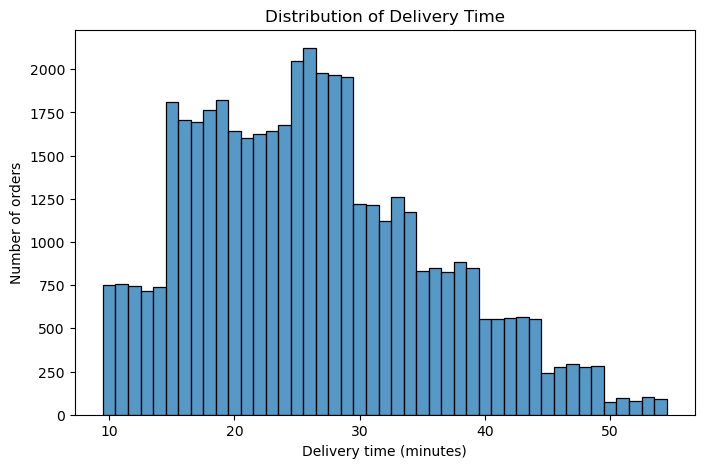

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(df_eda["Time_taken(min)"], discrete=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.show()

In [15]:
print(df_eda["Time_taken(min)"].describe())

count    45593.000000
mean        26.294607
std          9.383806
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: Time_taken(min), dtype: float64


In [16]:
print("Most frequent delivery time:", df_eda["Time_taken(min)"].mode()[0])

Most frequent delivery time: 26


<div dir="rtl">

- **الملاحظة:** أظهرت الرسمة أن أكثر وقت توصيل تكرر في البيانات هو 26 دقيقة، وهو قريب من توقعي السابق. وكمان المتوسط (26.3 دقيقة) والوسيط (26 دقيقة) متقاربين، مما يدل على أن أغلب الطلبات تتم حول هذا الوقت. ولاحظت برضو أن عدد الطلبات يبدأ بالانخفاض بشكل واضح بعد 40 دقيقة، بينما ما زال فيه عدد جيد من الطلبات الي تصل خلال 10 إلى 12 دقيقة، لذلك التوزيع مو متماثل بالكامل ويوجد امتداد للأوقات الأطول. أقل وقت توصيل كان 10 دقائق وأعلى وقت كان 54 دقيقة، وما ظهرت قيم سالبة أو غير منطقية

</div>